# Visualisation Group Work

You can use this notebook as a template and add your plots in the cells below. We've already added some code to import the necessary packages and included an example plot to show you how a good plot might look like. 

Now it's you your turn to create your first plots with Python's plotting libraries. At the end of this exercise your notebook should contain one plot per library. Since you will share your notebook with the other groups, make sure to add comments so it's easy for them to understand your code. 

Your group number will tell you which kind of plot and data set you should use for the exercise. 

| Group | Plot | Dataset | 
|-------|------|---------|
|  1 | Scatterplot | Seattle Weather |
|  2 | Lineplot | Seattle Weather | 
|  3 | Barchart | Seattle Weather  | 
|  4 | Geographical Maps | Airports  | 
 



## What makes a plot good?

For this exercise the charts do not have to be particularly fancy or provide mind-blowing insights into the data, but they should contain all the elements that make a good plot.
Take the following plot as an example:

![example_plot](assets/example_plot.png)

Like the plot above your figures should have/be...
1. ... a meaningful title.
2. ... labels (with units when necessary) on both axis. 
3. ... a legend (if necessary). Make sure it doesn't overlap other important elements.
3. ... text that is easliy readable. You can change and increase the font size, rotate tick labels, flip axis etc. to improve readabilty. 
4. ... not overloaded with information. Try to keep it rather clean and simple.

In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Import Data
Start by importing the data. We added some lines of code for the groups that work with the seattle weather data to help you get started. Depending on how you name your dataframe, you might have to slightly adjust the code in the cell below.

In [2]:
# Import data

In [3]:
# You might have to adjust the code in this cell if you named your dataframe differently
# Convert date to datetime format
df_weather.date = pd.to_datetime(df_weather.date)

# Create new column for year
df_weather["year"] = df_weather.date.dt.year

# Create new column for year-month
df_weather["year_month"] = df_weather["date"].dt.strftime("%Y-%m")
df_weather.head()

NameError: name 'df_weather' is not defined

## 1. Matplotlib

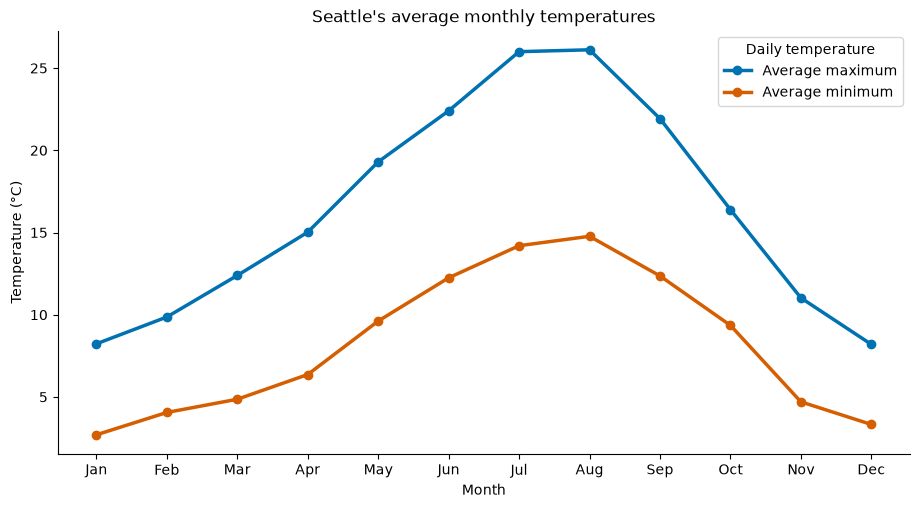

In [5]:
import pandas as pd

weather = pd.read_csv("data_group_work/seattle-weather.csv")
weather["date"] = pd.to_datetime(weather["date"])

monthly_temperature = (
    weather.assign(month=weather["date"].dt.month)
    .groupby("month", as_index=False)[["temp_max", "temp_min"]]
    .mean()
)

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_order = list(range(1, 13))

monthly_temperature

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.express as px

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = {"Average maximum": "#0072B2", "Average minimum": "#D55E00"}

ax.plot(monthly_temperature["month"], monthly_temperature["temp_max"],
        marker="o", linewidth=2.5, color=colors["Average maximum"], label="Average maximum")
ax.plot(monthly_temperature["month"], monthly_temperature["temp_min"],
        marker="o", linewidth=2.5, color=colors["Average minimum"], label="Average minimum")

ax.set(title="Seattle's average monthly temperatures", xlabel="Month", ylabel="Temperature (°C)")
ax.set_xticks(month_order, month_labels)
ax.legend(title="Daily temperature")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 2. Seaborn

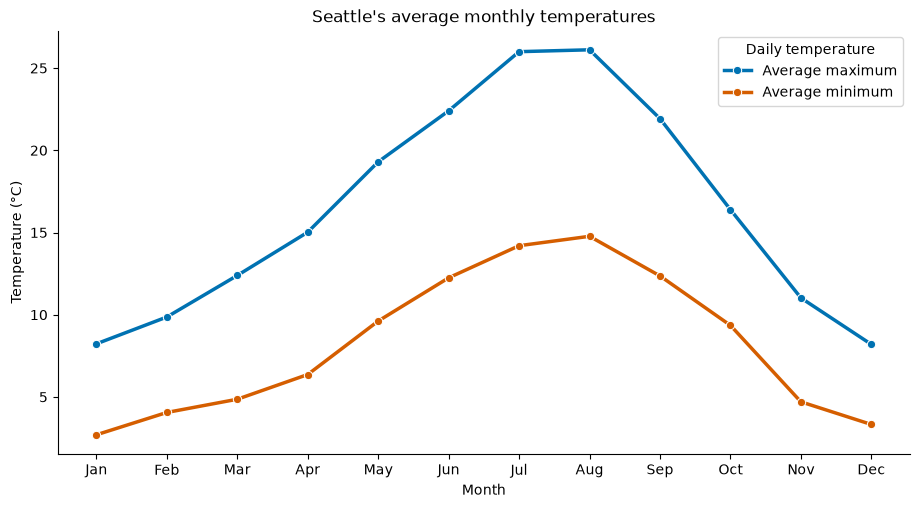

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.lineplot(
    data=monthly_long, x="month", y="temperature_c", hue="temperature_type",
    palette=colors, marker="o", linewidth=2.5, ax=ax
)
ax.set(title="Seattle's average monthly temperatures", xlabel="Month", ylabel="Temperature (°C)")
ax.set_xticks(month_order, month_labels)
ax.legend(title="Daily temperature")
sns.despine()
plt.show()

## 3. Plotly

In [ ]:
fig = px.line(
    monthly_long, x="month", y="temperature_c", color="temperature_type",
    markers=True, color_discrete_map=colors,
    title="Seattle's average monthly temperatures",
    labels={"month": "Month", "temperature_c": "Temperature (°C)",
            "temperature_type": "Daily temperature"},
)
fig.update_xaxes(tickmode="array", tickvals=month_order, ticktext=month_labels)
fig.update_layout(template="plotly_white", legend_title_text="Daily temperature", hovermode="x unified")
fig.show()